<a href="https://colab.research.google.com/github/anitejpadyana/BIS-lab/blob/main/Grey_Wolf_Optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

GREY WOLF OPTIMIZER RESULTS
--------------------------------
Best Fitness: 149.74

Optimized Drone Waypoints:
Waypoint 1: (0.53, 3.36)
Waypoint 2: (0.25, 7.42)
Waypoint 3: (13.18, 37.29)
Waypoint 4: (68.85, 90.85)

Total Path Distance: 149.74


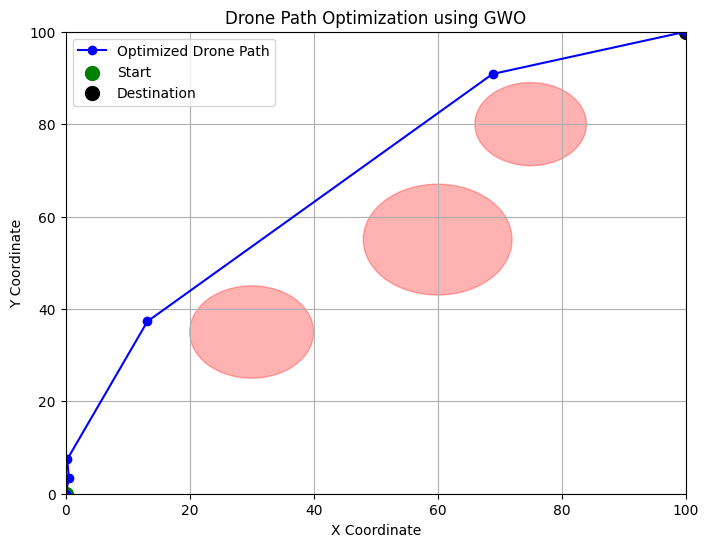

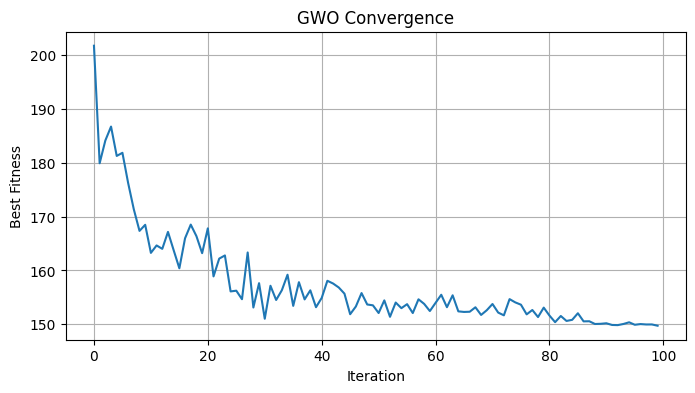

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

START = np.array([0.0, 0.0])
GOAL = np.array([100.0, 100.0])

N = 20
D = 8
MaxIter = 100

x_min = 0
x_max = 100

obstacles = [
    (30, 35, 10),
    (60, 55, 12),
    (75, 80, 9)
]

def point_to_segment_distance(point, a, b):
    ab = b - a
    t = np.dot(point - a, ab) / (np.dot(ab, ab) + 1e-10)
    t = np.clip(t, 0, 1)
    closest = a + t * ab
    return np.linalg.norm(point - closest)

def objective(X):
    waypoints = X.reshape(4, 2)
    path = np.vstack([START, waypoints, GOAL])

    total_distance = 0

    for i in range(len(path) - 1):
        total_distance += np.linalg.norm(path[i+1] - path[i])

    penalty = 0

    for obstacle in obstacles:
        ox, oy, radius = obstacle
        center = np.array([ox, oy])

        for i in range(len(path) - 1):
            dist = point_to_segment_distance(
                center, path[i], path[i+1]
            )

            if dist < radius + 3:
                penalty += 1000 * (radius + 3 - dist) ** 2

    return total_distance + penalty

def GreyWolfOptimizer():
    X = np.random.uniform(x_min, x_max, (N, D))
    fit = np.array([objective(wolf) for wolf in X])

    best_fitness_history = []

    for t in range(MaxIter):
        order = np.argsort(fit)

        X_alpha = X[order[0]].copy()
        X_beta = X[order[1]].copy()
        X_delta = X[order[2]].copy()

        a = 2 - 2 * (t / MaxIter)

        new_X = np.zeros_like(X)

        for i in range(N):
            guides = []

            for leader in [X_alpha, X_beta, X_delta]:
                r1 = np.random.rand(D)
                r2 = np.random.rand(D)

                A = 2 * a * r1 - a
                C = 2 * r2

                distance = np.abs(C * leader - X[i])
                new_position = leader - A * distance

                guides.append(new_position)

            new_X[i] = (
                guides[0] + guides[1] + guides[2]
            ) / 3

            new_X[i] = np.clip(new_X[i], x_min, x_max)

        X = new_X
        fit = np.array([objective(wolf) for wolf in X])

        best_fitness_history.append(np.min(fit))

    best_index = np.argmin(fit)
    best_solution = X[best_index]

    return best_solution, fit[best_index], best_fitness_history

best_path, best_fitness, history = GreyWolfOptimizer()

waypoints = best_path.reshape(4, 2)
final_path = np.vstack([START, waypoints, GOAL])

print("GREY WOLF OPTIMIZER RESULTS")
print("--------------------------------")
print("Best Fitness:", round(best_fitness, 2))
print("\nOptimized Drone Waypoints:")

for i, point in enumerate(waypoints):
    print(f"Waypoint {i+1}: ({point[0]:.2f}, {point[1]:.2f})")

print("\nTotal Path Distance:",
      round(sum(np.linalg.norm(final_path[i+1] - final_path[i])
                for i in range(len(final_path)-1)), 2))

plt.figure(figsize=(8, 6))

for ox, oy, radius in obstacles:
    circle = plt.Circle((ox, oy), radius, color='red', alpha=0.3)
    plt.gca().add_patch(circle)

plt.plot(final_path[:, 0], final_path[:, 1],
         'b-o', label='Optimized Drone Path')

plt.scatter(*START, color='green', s=100, label='Start')
plt.scatter(*GOAL, color='black', s=100, label='Destination')

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Drone Path Optimization using GWO")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("GWO Convergence")
plt.grid()
plt.show()
